<a href="https://colab.research.google.com/github/russvanfossen/Data_Science_Portfolio/blob/main/f1data.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [74]:
import pandas as pd
import matplotlib as mpl
import numpy as np
from matplotlib import pyplot as plt
from matplotlib.collections import LineCollection
from urllib.parse import quote
import requests

In [127]:
date_start = "2026-10-01"
date_end = "2026-10-31"

#https://api.openf1.org/v1/sessions?date_start%3E%3D2026-09-01&date_end%3C%3D2026-10-30
url = f"https://api.openf1.org/v1/sessions?date_start%3E%3D{date_start}&date_end%3C%3D{date_end}"
print(url)
# Load JSON directly from URL into DataFrame
df = pd.read_json(url)

# Display the first few rows
print(df.tail())

https://api.openf1.org/v1/sessions?date_start%3E%3D2026-10-01&date_end%3C%3D2026-10-31
    session_key session_type session_name                 date_start  \
14        11396         Race         Race  2026-10-25T20:00:00+00:00   
15        11397     Practice   Practice 1  2026-10-30T18:30:00+00:00   
16        11398     Practice   Practice 2  2026-10-30T22:00:00+00:00   
17        11399     Practice   Practice 3  2026-10-31T17:30:00+00:00   
18        11400   Qualifying   Qualifying  2026-10-31T21:00:00+00:00   

                     date_end  meeting_key  circuit_key circuit_short_name  \
14  2026-10-25T22:00:00+00:00         1297            9             Austin   
15  2026-10-30T19:30:00+00:00         1298           65        Mexico City   
16  2026-10-30T23:00:00+00:00         1298           65        Mexico City   
17  2026-10-31T18:30:00+00:00         1298           65        Mexico City   
18  2026-10-31T22:00:00+00:00         1298           65        Mexico City   

    country

,session_key,session_type,session_name,date_start,date_end,meeting_key,circuit_key,circuit_short_name,country_key,country_code,country_name,location,gmt_offset,year,is_cancelled


In [3]:
df.loc[df['circuit_short_name']=='Singapore']

,session_key,session_type,session_name,date_start,date_end,meeting_key,circuit_key,circuit_short_name,country_key,country_code,country_name,location,gmt_offset,year,is_cancelled
5,11378,Practice,Practice 1,2026-10-09T08:30:00+00:00,2026-10-09T09:30:00+00:00,1296,61,Singapore,157,SGP,Singapore,Marina Bay,08:00:00,2026,False
6,11379,Qualifying,Sprint Qualifying,2026-10-09T12:30:00+00:00,2026-10-09T13:14:00+00:00,1296,61,Singapore,157,SGP,Singapore,Marina Bay,08:00:00,2026,False
7,11383,Race,Sprint,2026-10-10T09:00:00+00:00,2026-10-10T09:30:00+00:00,1296,61,Singapore,157,SGP,Singapore,Marina Bay,08:00:00,2026,False
8,11384,Qualifying,Qualifying,2026-10-10T13:00:00+00:00,2026-10-10T14:00:00+00:00,1296,61,Singapore,157,SGP,Singapore,Marina Bay,08:00:00,2026,False
9,11388,Race,Race,2026-10-11T12:00:00+00:00,2026-10-11T14:00:00+00:00,1296,61,Singapore,157,SGP,Singapore,Marina Bay,08:00:00,2026,False


In [131]:
laps_df = pd.DataFrame()
session_key = 11388
driver_number = 3
start_lap_number = 1
end_lap_number = 1

#laps_url = f'https://api.openf1.org/v1/laps?session_key={session_key}&driver_number={driver_number}&lap_number={lap_number}'

for lap_number in range(start_lap_number, end_lap_number+1):
  laps_url = f'https://api.openf1.org/v1/laps?session_key={session_key}&driver_number={driver_number}&lap_number={lap_number}'
  laps_df = pd.concat([laps_df, pd.read_json(laps_url)])

laps_df



,meeting_key,session_key,driver_number,lap_number,date_start,duration_sector_1,duration_sector_2,duration_sector_3,i1_speed,i2_speed,is_pit_out_lap,lap_duration,segments_sector_1,segments_sector_2,segments_sector_3,st_speed
0,1296,11388,3,1,2026-10-11T12:03:39.077000+00:00,32.691,41.59,28.394,290,252,False,102.675,"[None, 2049, 2049, 2051, 2051, 2049, 2049, 2049]","[2051, 2051, 2049, 2049, 2051, 2051, 2051, 2049]","[2049, 2049, 2049, 2049, 2049, 2049, 2049, 2051]",189


In [136]:
session_name = df.loc[df['session_key'] == session_key, 'circuit_short_name'].iloc[0]
session_name

'Singapore'

In [65]:
nlaps_df = laps_df.copy()
nlaps_df['date_end'] = pd.to_datetime(nlaps_df['date_start'], utc=True) + pd.to_timedelta(nlaps_df['lap_duration'], unit='s')
nlaps_df['date_start'] = nlaps_df['date_start'].astype('string')
nlaps_df['date_end'] = nlaps_df['date_end'].astype('string')
nlaps_df
nlaps_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1 entries, 0 to 0
Data columns (total 17 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   meeting_key        1 non-null      int64  
 1   session_key        1 non-null      int64  
 2   driver_number      1 non-null      int64  
 3   lap_number         1 non-null      int64  
 4   date_start         1 non-null      string 
 5   duration_sector_1  1 non-null      float64
 6   duration_sector_2  1 non-null      float64
 7   duration_sector_3  1 non-null      float64
 8   i1_speed           1 non-null      int64  
 9   i2_speed           1 non-null      int64  
 10  is_pit_out_lap     1 non-null      bool   
 11  lap_duration       1 non-null      float64
 12  segments_sector_1  1 non-null      object 
 13  segments_sector_2  1 non-null      object 
 14  segments_sector_3  1 non-null      object 
 15  st_speed           1 non-null      int64  
 16  date_end           1 non-null 

In [71]:
start = nlaps_df.iloc[0]['date_start'][:26]
end = nlaps_df.iloc[-1]['date_end'][:26]

location_url = f"https://api.openf1.org/v1/location?session_key={session_key}&driver_number={driver_number}&date>={start}&date<={end}"
location_url

'https://api.openf1.org/v1/location?session_key=11388&driver_number=3&date>=2026-10-11T12:03:39.077000&date<=2026-10-11 12:05:21.752000'

In [81]:
response = requests.get(location_url)



In [86]:
location_df = pd.DataFrame(response.json())
location_df

,date,session_key,meeting_key,y,x,driver_number,z
0,2026-10-11T12:03:39.271000+00:00,11388,1296,708,872,3,188
1,2026-10-11T12:03:39.411000+00:00,11388,1296,708,872,3,188
2,2026-10-11T12:03:39.691000+00:00,11388,1296,709,871,3,188
3,2026-10-11T12:03:39.851000+00:00,11388,1296,718,870,3,188
4,2026-10-11T12:03:40.271000+00:00,11388,1296,735,868,3,188
...,...,...,...,...,...,...,...
389,2026-10-11T12:05:20.191000+00:00,11388,1296,-1278,1167,3,189
390,2026-10-11T12:05:20.651000+00:00,11388,1296,-1093,1151,3,189
391,2026-10-11T12:05:20.871000+00:00,11388,1296,-885,1124,3,188
392,2026-10-11T12:05:21.251000+00:00,11388,1296,-637,1083,3,188


In [89]:
location_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 394 entries, 0 to 393
Data columns (total 7 columns):
 #   Column         Non-Null Count  Dtype              
---  ------         --------------  -----              
 0   date           394 non-null    datetime64[ns, UTC]
 1   session_key    394 non-null    int64              
 2   meeting_key    394 non-null    int64              
 3   y              394 non-null    int64              
 4   x              394 non-null    int64              
 5   driver_number  394 non-null    int64              
 6   z              394 non-null    int64              
dtypes: datetime64[ns, UTC](1), int64(6)
memory usage: 21.7 KB


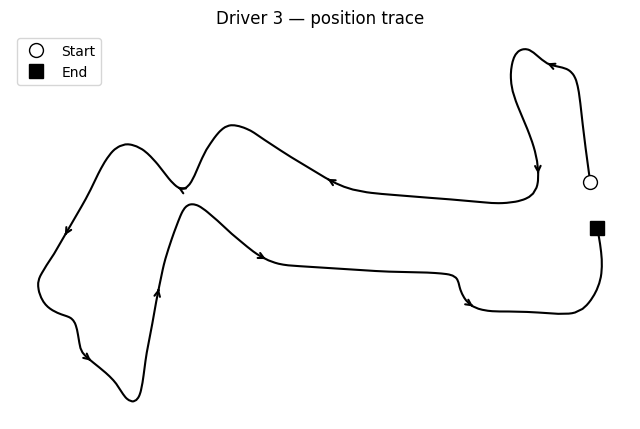

In [93]:

import matplotlib.pyplot as plt

location_df["date"] = pd.to_datetime(location_df["date"], format="ISO8601", utc=True)
location_df = location_df.sort_values("date")

fig, ax = plt.subplots(figsize=(8, 8))

# The path itself
ax.plot(location_df["x"], location_df["y"], color="black", linewidth=1.5)

# Start and end points, told apart by shape
ax.plot(location_df["x"].iloc[0], location_df["y"].iloc[0], marker="o", markersize=10,
        markerfacecolor="white", markeredgecolor="black", linestyle="none", label="Start")
ax.plot(location_df["x"].iloc[-1], location_df["y"].iloc[-1], marker="s", markersize=10,
        color="black", linestyle="none", label="End")

# Direction arrows about every 40 points
step = 40
for i in range(0, len(location_df) - 1, step):
    ax.annotate("", xy=(location_df["x"].iloc[i + 1], location_df["y"].iloc[i + 1]),
                xytext=(location_df["x"].iloc[i], location_df["y"].iloc[i]),
                arrowprops=dict(arrowstyle="->", lw=1.5, color="black"))

ax.set_aspect("equal")  # keeps the track from looking stretched
ax.axis("off")
ax.set_title("Driver 3 — position trace")
ax.legend()

plt.show()

In [94]:
car_url = f"https://api.openf1.org/v1/car_data?session_key={session_key}&driver_number={driver_number}&date>={start}&date<={end}"
car_url

'https://api.openf1.org/v1/car_data?session_key=11388&driver_number=3&date>=2026-10-11T12:03:39.077000&date<=2026-10-11 12:05:21.752000'

In [95]:
response = requests.get(car_url)
car_df = pd.DataFrame(response.json())
car_df

,date,session_key,rpm,n_gear,brake,drs,throttle,driver_number,meeting_key,speed
0,2026-10-11T12:03:39.105000+00:00,11388,11315,1,0,None,20,3,1296,0
1,2026-10-11T12:03:39.385000+00:00,11388,11260,1,0,None,20,3,1296,0
2,2026-10-11T12:03:39.545000+00:00,11388,10280,1,0,None,20,3,1296,0
3,2026-10-11T12:03:39.744000+00:00,11388,8880,1,0,None,20,3,1296,10
4,2026-10-11T12:03:40.064000+00:00,11388,6640,1,0,None,20,3,1296,19
...,...,...,...,...,...,...,...,...,...,...
387,2026-10-11T12:05:20.624000+00:00,11388,10723,6,0,None,100,3,1296,235
388,2026-10-11T12:05:20.824000+00:00,11388,11050,6,0,None,100,3,1296,240
389,2026-10-11T12:05:20.985000+00:00,11388,10967,6,0,None,100,3,1296,241
390,2026-10-11T12:05:21.185000+00:00,11388,11130,6,0,None,100,3,1296,245


In [99]:
car_df['date'] = car_df['date'].astype('datetime64[ns, UTC]')
car_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 392 entries, 0 to 391
Data columns (total 10 columns):
 #   Column         Non-Null Count  Dtype              
---  ------         --------------  -----              
 0   date           392 non-null    datetime64[ns, UTC]
 1   session_key    392 non-null    int64              
 2   rpm            392 non-null    int64              
 3   n_gear         392 non-null    int64              
 4   brake          392 non-null    int64              
 5   drs            0 non-null      object             
 6   throttle       392 non-null    int64              
 7   driver_number  392 non-null    int64              
 8   meeting_key    392 non-null    int64              
 9   speed          392 non-null    int64              
dtypes: datetime64[ns, UTC](1), int64(8), object(1)
memory usage: 30.8+ KB


In [106]:
lap_data = pd.merge(location_df, car_df, on='date', how='outer')
lap_data

,date,session_key_x,meeting_key_x,y,x,driver_number_x,z,session_key_y,rpm,n_gear,brake,drs,throttle,driver_number_y,meeting_key_y,speed
0,2026-10-11 12:03:39.105000+00:00,NaN,NaN,NaN,NaN,NaN,NaN,11388.0,11315.0,1.0,0.0,None,20.0,3.0,1296.0,0.0
1,2026-10-11 12:03:39.271000+00:00,11388.0,1296.0,708.0,872.0,3.0,188.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,2026-10-11 12:03:39.385000+00:00,NaN,NaN,NaN,NaN,NaN,NaN,11388.0,11260.0,1.0,0.0,None,20.0,3.0,1296.0,0.0
3,2026-10-11 12:03:39.411000+00:00,11388.0,1296.0,708.0,872.0,3.0,188.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,2026-10-11 12:03:39.545000+00:00,NaN,NaN,NaN,NaN,NaN,NaN,11388.0,10280.0,1.0,0.0,None,20.0,3.0,1296.0,0.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
781,2026-10-11 12:05:20.985000+00:00,NaN,NaN,NaN,NaN,NaN,NaN,11388.0,10967.0,6.0,0.0,None,100.0,3.0,1296.0,241.0
782,2026-10-11 12:05:21.185000+00:00,NaN,NaN,NaN,NaN,NaN,NaN,11388.0,11130.0,6.0,0.0,None,100.0,3.0,1296.0,245.0
783,2026-10-11 12:05:21.251000+00:00,11388.0,1296.0,-637.0,1083.0,3.0,188.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
784,2026-10-11 12:05:21.625000+00:00,NaN,NaN,NaN,NaN,NaN,NaN,11388.0,11430.0,6.0,0.0,None,100.0,3.0,1296.0,251.0


In [108]:
lap_data = lap_data.sort_values('date').set_index('date')

In [110]:
lap_data['speed_interp'] = lap_data['speed'].interpolate(method='time')


In [117]:
loc = lap_data.dropna(subset=['x','y','speed_interp'])
loc

,session_key_x,meeting_key_x,y,x,driver_number_x,z,session_key_y,rpm,n_gear,brake,drs,throttle,driver_number_y,meeting_key_y,speed,speed_interp
date,,,,,,,,,,,,,,,,
2026-10-11 12:03:39.271000+00:00,11388.0,1296.0,708.0,872.0,3.0,188.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.000000
2026-10-11 12:03:39.411000+00:00,11388.0,1296.0,708.0,872.0,3.0,188.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.000000
2026-10-11 12:03:39.691000+00:00,11388.0,1296.0,709.0,871.0,3.0,188.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,7.336687
2026-10-11 12:03:39.851000+00:00,11388.0,1296.0,718.0,870.0,3.0,188.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,13.009377
2026-10-11 12:03:40.271000+00:00,11388.0,1296.0,735.0,868.0,3.0,188.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,26.392859
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2026-10-11 12:05:20.191000+00:00,11388.0,1296.0,-1278.0,1167.0,3.0,189.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,226.150003
2026-10-11 12:05:20.651000+00:00,11388.0,1296.0,-1093.0,1151.0,3.0,189.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,235.675002
2026-10-11 12:05:20.871000+00:00,11388.0,1296.0,-885.0,1124.0,3.0,188.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,240.291926


In [119]:
points = loc[['x','y']].to_numpy().reshape(-1, 1, 2)
points

array([[[ 8.7200e+02,  7.0800e+02]],

       [[ 8.7200e+02,  7.0800e+02]],

       [[ 8.7100e+02,  7.0900e+02]],

       [[ 8.7000e+02,  7.1800e+02]],

       [[ 8.6800e+02,  7.3500e+02]],

       [[ 8.6600e+02,  7.4400e+02]],

       [[ 8.6400e+02,  7.6100e+02]],

       [[ 8.5700e+02,  8.0700e+02]],

       [[ 8.5100e+02,  8.5400e+02]],

       [[ 8.4700e+02,  8.7800e+02]],

       [[ 8.4300e+02,  9.0800e+02]],

       [[ 8.3800e+02,  9.4500e+02]],

       [[ 8.2100e+02,  1.0690e+03]],

       [[ 8.0600e+02,  1.1760e+03]],

       [[ 7.9600e+02,  1.2500e+03]],

       [[ 7.8000e+02,  1.3760e+03]],

       [[ 7.5600e+02,  1.5560e+03]],

       [[ 7.3300e+02,  1.7390e+03]],

       [[ 7.1700e+02,  1.8720e+03]],

       [[ 7.0400e+02,  1.9800e+03]],

       [[ 6.8200e+02,  2.1590e+03]],

       [[ 6.5600e+02,  2.3960e+03]],

       [[ 6.3400e+02,  2.5950e+03]],

       [[ 6.2000e+02,  2.7090e+03]],

       [[ 5.9400e+02,  2.9150e+03]],

       [[ 5.8200e+02,  2.9910e+03]],

       [[ 5.

In [120]:
segments = np.concatenate([points[:-1], points[1:]], axis=1)
segments

array([[[  872.,   708.],
        [  872.,   708.]],

       [[  872.,   708.],
        [  871.,   709.]],

       [[  871.,   709.],
        [  870.,   718.]],

       ...,

       [[ 1151., -1093.],
        [ 1124.,  -885.]],

       [[ 1124.,  -885.],
        [ 1083.,  -637.]],

       [[ 1083.,  -637.],
        [ 1056.,  -474.]]], shape=(393, 2, 2))

In [121]:
speed = loc['speed_interp'].to_numpy()
seg_speed = (speed[:-1] + speed[1:]) / 2
seg_speed

array([  0.        ,   3.66834374,  10.17303214,  19.70111811,
        28.28393051,  32.4250016 ,  39.94250176,  52.49875189,
        61.82916853,  66.86875236,  73.86666951,  85.79848221,
       102.00126087, 118.28384433, 133.11364364, 149.97372393,
       168.9531224 , 183.4375032 , 193.671884  , 200.9921912 ,
       210.07499776, 221.83750016, 228.61999936, 222.74499136,
       204.3187368 , 178.17401667, 154.85110494, 136.62082987,
       120.96749696, 111.68499712, 103.07545216,  95.40681629,
        90.87136221,  87.87785655,  86.90535726,  89.60383975,
        93.88509072, 102.8406296 , 111.6625068 , 116.72455903,
       125.06518263, 131.58333547, 133.01041707, 131.5312512 ,
       126.8229184 , 120.4687456 , 113.22915627, 102.13541227,
        90.5078144 ,  81.82713047,  75.14999738,  71.14318051,
        70.        ,  71.37735914,  73.71235946,  78.45062619,
        87.41250187,  99.70759143, 108.33393097, 114.83571652,
       124.9475013 , 132.21625312, 145.34334998, 160.31

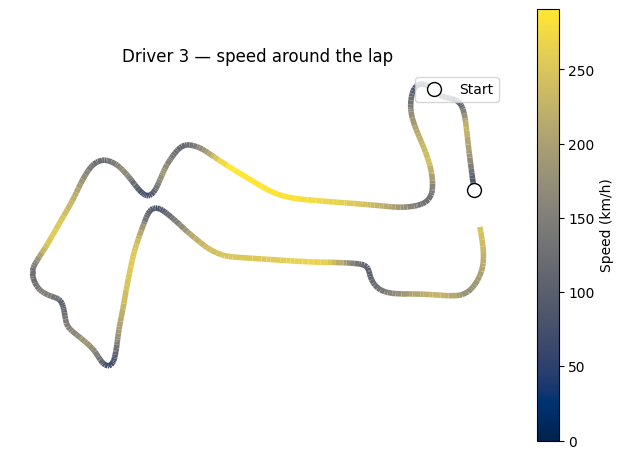

In [122]:
from matplotlib.collections import LineCollection
fig, ax = plt.subplots(figsize=(12, 8))
lc = LineCollection(segments, cmap="cividis", linewidths=4)
lc.set_array(seg_speed)
ax.add_collection(lc)

# Start marker
ax.plot(loc["x"].iloc[0], loc["y"].iloc[0], marker="o", markersize=10,
        markerfacecolor="white", markeredgecolor="black", linestyle="none", label="Start")

ax.autoscale()
ax.set_aspect("equal")
ax.axis("off")
ax.legend(loc="upper right")
fig.colorbar(lc, ax=ax, label="Speed (km/h)", shrink=0.7)
ax.set_title("Driver 3 — speed around the lap")
plt.show()

In [137]:
from matplotlib.animation import FuncAnimation
from matplotlib.collections import LineCollection
from IPython.display import HTML

# Uses `loc`, `segments` and `seg_speed` from the previous code
xs, ys = loc["x"].to_numpy(), loc["y"].to_numpy()
speeds = loc["speed_interp"].to_numpy()

# Playback speed: 1 = real time, 4 = 4x faster
speedup = 4
avg_dt_ms = loc.index.to_series().diff().dt.total_seconds().mean() * 1000
interval = avg_dt_ms / speedup

fig, ax = plt.subplots(figsize=(7, 7), dpi=80)

# Faint full track so the shape is visible from the start
ax.plot(xs, ys, color="lightgray", linewidth=6, zorder=1)

# Colored line that grows over time (color range fixed so it doesn't shift)
lc = LineCollection([], cmap="YlOrRd", linewidths=4, zorder=2)
lc.set_clim(seg_speed.min(), seg_speed.max())
ax.add_collection(lc)

# Car marker and speed readout
car, = ax.plot([], [], marker="o", markersize=12, markerfacecolor="white",
               markeredgecolor="black", markeredgewidth=2, linestyle="none", zorder=3)
speed_text = ax.text(0.02, 0.98, "", transform=ax.transAxes, va="top",
                     fontsize=14, family="monospace")

ax.set_aspect("equal")
ax.axis("off")
pad = 200
ax.set_xlim(xs.min() - pad, xs.max() + pad)
ax.set_ylim(ys.min() - pad, ys.max() + pad)
fig.colorbar(lc, ax=ax, label="Speed (km/h)", shrink=0.7)
ax.set_title(f"{session_name} \n Driver {driver_number} — speed around the lap")

def update(i):
    lc.set_segments(segments[:i])
    lc.set_array(seg_speed[:i])
    car.set_data([xs[i]], [ys[i]])
    speed_text.set_text(f"{speeds[i]:5.0f} km/h")
    return lc, car, speed_text

anim = FuncAnimation(fig, update, frames=range(1, len(xs)),
                     interval=interval, blit=True)
plt.close(fig)  # stops Colab from also showing a still copy

HTML(anim.to_jshtml())